# Inspección de manzanas en video

La primera parte repite lo que muestra el informe sobre el video de Coral: la Figura 4, el conteo de las 18 pasadas y los avisos de daño visible por pasada.

La segunda parte prueba un cambio. En el video cada recuadro muestra la decisión de un solo cuadro, así que la etiqueta de una misma manzana puede cambiar mientras pasa. Proponemos una sola decisión por manzana: el promedio de `p_danio` de todos los cuadros que comparten su ID de ByteTrack, con el mismo umbral de 0,50 y al menos 5 cuadros. Este video ya se consultó durante el desarrollo, así que el resultado no es una validación nueva.

Para procesar otro video o usar una cámara, ejecutá la instalación, la celda de preparación y la última sección. Los resultados de Coral están guardados en las celdas.

In [3]:
%pip install -q ultralytics==8.4.192 lap==0.5.13

In [4]:
import csv
import json
import subprocess
import sys
import time
from collections import Counter, defaultdict
from datetime import datetime, timezone
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import Video, display
from matplotlib import get_data_path
from PIL import ImageFont
from sklearn.metrics import ConfusionMatrixDisplay

if not torch.cuda.is_available():
    raise RuntimeError('Elegí un entorno con GPU en Colab.')

repo = Path('/content/inspeccion-manzanas-entrega')
if not (repo / '.git').is_dir():
    subprocess.run(['git', 'clone', '--depth', '1',
                    'https://github.com/MauroProto/inspeccion-de-manzanas.git', str(repo)], check=True)
sys.path.insert(0, str(repo / 'notebooks' / 'apoyo'))
from inspeccion import Inspeccion

pesos = repo / 'pesos'
inspeccion = Inspeccion(pesos / 'yolo_manzanas.pt', pesos / 'cnn_variedades.pt',
                        pesos / 'cnn_danio_visible.pt', pesos_confirmacion=pesos / 'cnn_confirmacion_danio.pt')
umbral = inspeccion.umbral_danio
video = repo / 'videos' / 'coral_manzanas.mp4'
with (repo / 'datos' / 'anotaciones' / 'coral_estado_visible.csv').open(encoding='utf-8-sig', newline='') as archivo:
    referencias = list(csv.DictReader(archivo))
fuente = ImageFont.truetype(str(Path(get_data_path()) / 'fonts/ttf/DejaVuSans.ttf'), 16)
fecha = datetime.now(timezone.utc).strftime('%Y-%m-%d_%H%M%S_%f')
salida = Path('/content/resultados/inspeccion_en_video') / fecha
salida.mkdir(parents=True)
print('GPU:', torch.cuda.get_device_name(0))
print('Salida:', salida)


GPU: Tesla T4


## Procesar todo el video

Usamos la misma clase `Inspeccion` y los mismos pesos que la demo: YOLO11n, ByteTrack, la red de variedad y las dos redes de daño. Guardamos una fila por recuadro con su ID, su variedad y su puntaje de daño `p_danio`.

In [5]:
from seguimiento import ContadorCruces
from coral import dibujar, evaluar_pasadas

inspeccion.reiniciar_seguimiento()
captura = cv2.VideoCapture(str(video))
fps = captura.get(cv2.CAP_PROP_FPS)
filas = []
inicio = time.perf_counter()
while True:
    imagenes = []
    for _ in range(12):
        ok, imagen = captura.read()
        if not ok:
            break
        imagenes.append(imagen)
    if not imagenes:
        break
    for cajas in inspeccion.procesar_lote(imagenes):
        filas.extend(cajas)
captura.release()
cuadros_por_segundo = inspeccion.cuadro / (time.perf_counter() - inicio)
print(len(filas), 'recuadros en', inspeccion.cuadro, 'cuadros')
print(round(cuadros_por_segundo, 1), 'cuadros por segundo, sin guardar el video')

4001 recuadros en 6720 cuadros
68.9 cuadros por segundo, sin guardar el video


## Figura 4 del informe: cuadro 3.250

El cuadro original, la salida del sistema y el recorte que reciben las redes.

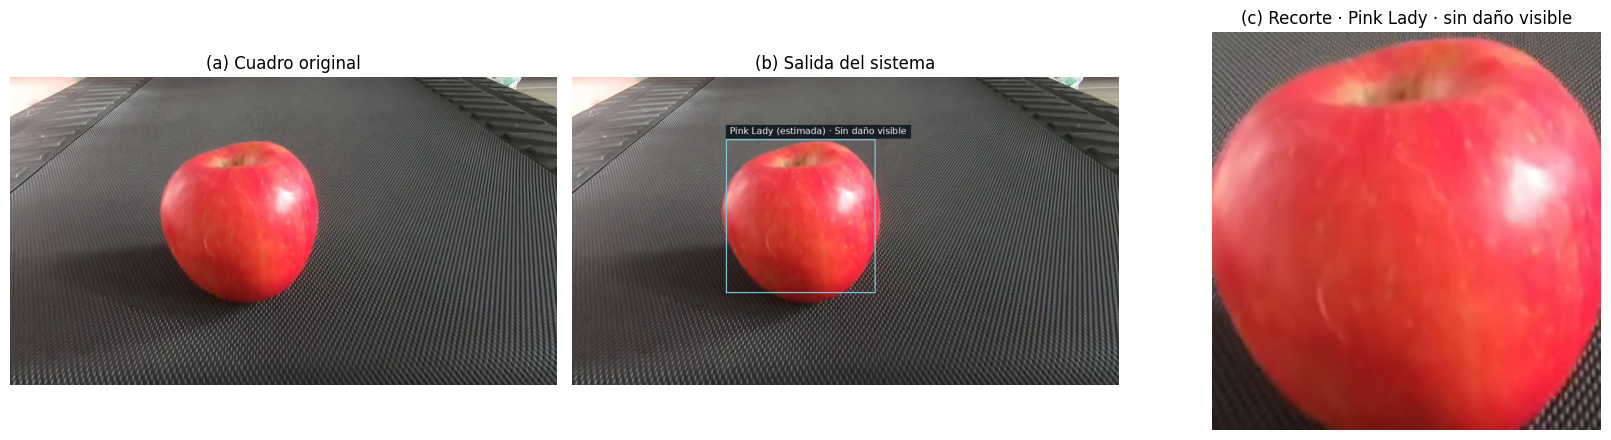

In [6]:
cuadro_figura = 3250
captura = cv2.VideoCapture(str(video))
captura.set(cv2.CAP_PROP_POS_FRAMES, cuadro_figura)
ok, imagen = captura.read()
captura.release()

cajas = [fila for fila in filas if fila['cuadro'] == cuadro_figura]
caja = cajas[0]
recorte = imagen[int(caja['y1']):int(caja['y2']), int(caja['x1']):int(caja['x2'])]
estado = 'con daño visible' if caja['p_danio'] >= umbral else 'sin daño visible'

figura, ejes = plt.subplots(1, 3, figsize=(17, 4.5))
ejes[0].imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
ejes[0].set_title('(a) Cuadro original')
ejes[1].imshow(cv2.cvtColor(dibujar(imagen, cajas, umbral, fuente), cv2.COLOR_BGR2RGB))
ejes[1].set_title('(b) Salida del sistema')
ejes[2].imshow(cv2.cvtColor(recorte, cv2.COLOR_BGR2RGB))
ejes[2].set_title(f"(c) Recorte · {caja['variedad']} · {estado}")
for eje in ejes:
    eje.axis('off')
plt.tight_layout()
plt.savefig(salida / 'figura_4.png', dpi=150)
plt.show()

## Conteo de pasadas

Contamos una pasada cuando el centro del recuadro de un ID cruza la línea de conteo. Comparamos cada cruce con el tramo de cuadros que anotamos a mano para esa pasada.

In [7]:
contador = ContadorCruces()
for fila in filas:
    contador.actualizar(fila['cuadro'], fila['id'], (fila['x1'], fila['y1'], fila['x2'], fila['y2']))
cruces = [cruce['cuadro_estimado'] for cruce in contador.cruces]

tabla_cruces = []
for referencia in referencias:
    desde, hasta = int(referencia['cuadro_desde']), int(referencia['cuadro_hasta'])
    cruce = min(cruces, key=lambda cuadro: abs(cuadro - hasta))
    tabla_cruces.append({'pasada': referencia['manzana'], 'tramo anotado': f'{desde} a {hasta}', 'cruce': cruce,
                         'dentro del tramo': desde <= cruce <= hasta,
                         'cuadros después del tramo': max(0, cruce - hasta)})
tabla_cruces = pd.DataFrame(tabla_cruces)
display(tabla_cruces)
cruces_en_tramo = int(tabla_cruces['dentro del tramo'].sum())
print('Cruces contados:', contador.total)
print('Dentro del tramo anotado:', cruces_en_tramo, 'de', len(tabla_cruces))

,pasada,tramo anotado,cruce,dentro del tramo,cuadros después del tramo
0,Pasada 01,670 a 700,694,True,0
1,Pasada 02,995 a 1025,1016,True,0
2,Pasada 03,1335 a 1365,1347,True,0
3,Pasada 04,1625 a 1655,1644,True,0
4,Pasada 05,1985 a 2015,2004,True,0
5,Pasada 06,2305 a 2335,2322,True,0
6,Pasada 07,2550 a 2580,2565,True,0
7,Pasada 08,2885 a 2915,2901,True,0
8,Pasada 09,3225 a 3255,3237,True,0
9,Pasada 10,3570 a 3600,3574,True,0


Cruces contados: 18
Dentro del tramo anotado: 16 de 18


## Daño visible por pasada, con la regla del informe

En los cuadros pares de cada pasada tomamos el recuadro con mayor confianza y promediamos su puntaje de daño. Hay aviso si el promedio llega a 0,50. La última columna es la observación que anotamos al mirar el video.

In [8]:
predichas = {}
for fila in filas:
    anterior = predichas.get(fila['cuadro'])
    if anterior is None or fila['score_detector'] > anterior['score_detector']:
        predichas[fila['cuadro']] = fila

por_pasada, detalle = evaluar_pasadas(referencias, predichas, umbral)
tabla_pasadas = pd.DataFrame(detalle)
tabla_pasadas['observación'] = [referencia['observacion'] for referencia in referencias]
display(tabla_pasadas[['pasada', 'real', 'prediccion', 'puntaje', 'observación']].round(2))

con_danio = tabla_pasadas[tabla_pasadas['real'] == 'defectuosa']
sin_danio = tabla_pasadas[tabla_pasadas['real'] == 'no defectuosa']
con_etiqueta = sin_danio[sin_danio['observación'] == 'Etiqueta comercial']
print('Avisos en pasadas con daño:', (con_danio['prediccion'] == 'defectuosa').sum(), 'de', len(con_danio))
print('Avisos falsos:', (sin_danio['prediccion'] == 'defectuosa').sum(), 'de', len(sin_danio))
print('Avisos falsos con etiqueta comercial:', (con_etiqueta['prediccion'] == 'defectuosa').sum(),
      'de', len(con_etiqueta))

,pasada,real,prediccion,puntaje,observación
0,Pasada 01,no defectuosa,no defectuosa,0.01,Superficie roja sin daño visible
1,Pasada 02,no defectuosa,defectuosa,0.80,Etiqueta comercial
2,Pasada 03,no defectuosa,no defectuosa,0.00,Superficie roja sin daño visible
3,Pasada 04,defectuosa,defectuosa,0.96,Podredumbre visible en el extremo
4,Pasada 05,no defectuosa,no defectuosa,0.40,Etiqueta comercial
5,Pasada 06,no defectuosa,no defectuosa,0.02,Superficie roja sin daño visible
6,Pasada 07,defectuosa,defectuosa,0.83,Zona marrón extensa con piel hundida
7,Pasada 08,no defectuosa,no defectuosa,0.11,Superficie visible y cavidad del tallo
8,Pasada 09,no defectuosa,no defectuosa,0.01,Superficie roja sin daño visible
9,Pasada 10,defectuosa,defectuosa,0.97,Podredumbre visible cerca del extremo


Avisos en pasadas con daño: 6 de 6
Avisos falsos: 3 de 12
Avisos falsos con etiqueta comercial: 3 de 4


Un recorte de cada pasada con su etiqueta real y lo que decidió el sistema. El título queda en verde cuando coinciden y en rojo cuando no.

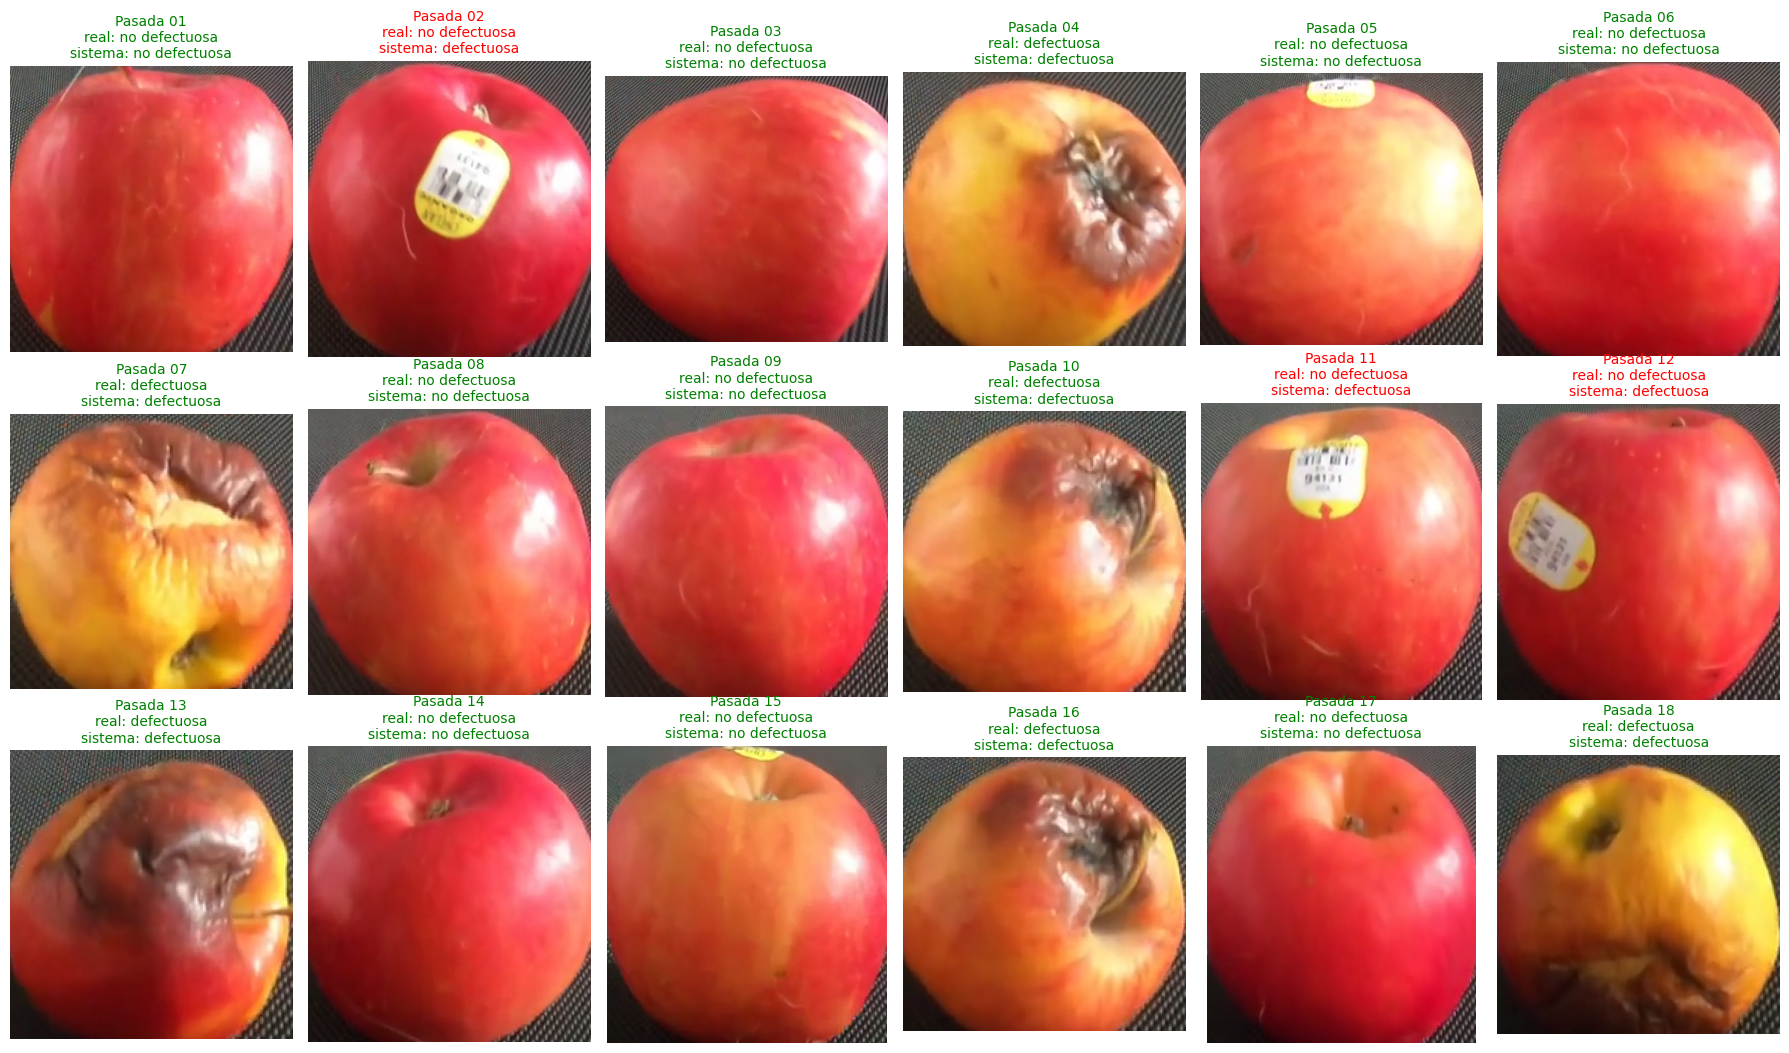

In [9]:
captura = cv2.VideoCapture(str(video))
figura, ejes = plt.subplots(3, 6, figsize=(18, 10.5))
for eje, pasada, referencia in zip(ejes.flat, detalle, referencias):
    cuadro = (int(referencia['cuadro_desde']) + int(referencia['cuadro_hasta'])) // 2
    captura.set(cv2.CAP_PROP_POS_FRAMES, cuadro)
    ok, imagen = captura.read()
    eje.axis('off')
    if ok and cuadro in predichas:
        fila = predichas[cuadro]
        recorte = imagen[int(fila['y1']):int(fila['y2']), int(fila['x1']):int(fila['x2'])]
        eje.imshow(cv2.cvtColor(recorte, cv2.COLOR_BGR2RGB))
    color = 'green' if pasada['prediccion'] == pasada['real'] else 'red'
    eje.set_title(f"{pasada['pasada']}\nreal: {pasada['real']}\nsistema: {pasada['prediccion']}",
                  color=color, fontsize=10)
captura.release()
plt.tight_layout()
plt.savefig(salida / 'pasadas.png', dpi=150)
plt.show()

## Propuesta: una decisión por manzana

Juntamos los recuadros de cada ID. El estado sale del promedio de `p_danio` y la variedad, del voto más repetido. Con menos de 5 cuadros la manzana queda sin decisión. También contamos cuántos cuadros mostraban una etiqueta distinta a la de su manzana.

In [10]:
minimo_cuadros = 5
por_id = defaultdict(list)
for fila in filas:
    if fila['id'] >= 0 and fila['p_danio'] is not None:
        por_id[fila['id']].append(fila)

manzanas = {}
for identificador, cajas in por_id.items():
    promedio = sum(caja['p_danio'] for caja in cajas) / len(cajas)
    if len(cajas) < minimo_cuadros:
        estado = 'sin decisión'
    elif promedio >= umbral:
        estado = 'defectuosa'
    else:
        estado = 'no defectuosa'
    variedad = Counter(caja['variedad'] for caja in cajas).most_common(1)[0][0]
    manzanas[identificador] = {
        'id': identificador, 'cuadros': len(cajas), 'desde': cajas[0]['cuadro'], 'hasta': cajas[-1]['cuadro'],
        'p_danio': promedio, 'estado': estado, 'variedad': variedad,
        'cuadros_con_otro_estado': sum((caja['p_danio'] >= umbral) != (promedio >= umbral) for caja in cajas),
        'cuadros_con_otra_variedad': sum(caja['variedad'] != variedad for caja in cajas),
    }

tabla_manzanas = pd.DataFrame(manzanas.values())
tabla_manzanas.to_csv(salida / 'manzanas.csv', index=False)
display(tabla_manzanas.round(2))

con_decision = tabla_manzanas[tabla_manzanas['estado'] != 'sin decisión']
cuadros_con_decision = int(con_decision['cuadros'].sum())
otro_estado = int(con_decision['cuadros_con_otro_estado'].sum())
otra_variedad = int(con_decision['cuadros_con_otra_variedad'].sum())
print(len(manzanas), 'IDs,', len(con_decision), 'con decisión')
print('Cuadros que mostraban otro estado:', otro_estado, 'de', cuadros_con_decision)
print('Cuadros que mostraban otra variedad:', otra_variedad, 'de', cuadros_con_decision)

,id,cuadros,desde,hasta,p_danio,estado,variedad,cuadros_con_otro_estado,cuadros_con_otra_variedad
0,1,171,571,741,0.05,no defectuosa,Pink Lady,3,68
1,2,190,877,1066,0.43,no defectuosa,Pink Lady,95,82
2,3,1,896,896,0.04,sin decisión,Crimson Snow,0,0
3,7,2,1050,1051,0.96,sin decisión,Pink Lady,0,0
4,8,198,1209,1406,0.05,no defectuosa,Crimson Snow,0,90
5,9,200,1497,1696,0.74,defectuosa,Pink Lady,53,4
6,10,204,1854,2057,0.21,no defectuosa,Pink Lady,19,29
7,11,1,2053,2053,0.31,sin decisión,Pink Lady,0,0
8,13,197,2176,2372,0.04,no defectuosa,Pink Lady,0,45
9,16,197,2426,2622,0.64,defectuosa,Pink Lady,63,9


23 IDs, 19 con decisión
Cuadros que mostraban otro estado: 702 de 3961
Cuadros que mostraban otra variedad: 852 de 3961


Los puntos grises son el puntaje de cada cuadro y cada línea gruesa es el promedio de una manzana. Los puntos que cruzan el umbral dentro de una misma manzana son los cambios de etiqueta que se ven en el video.

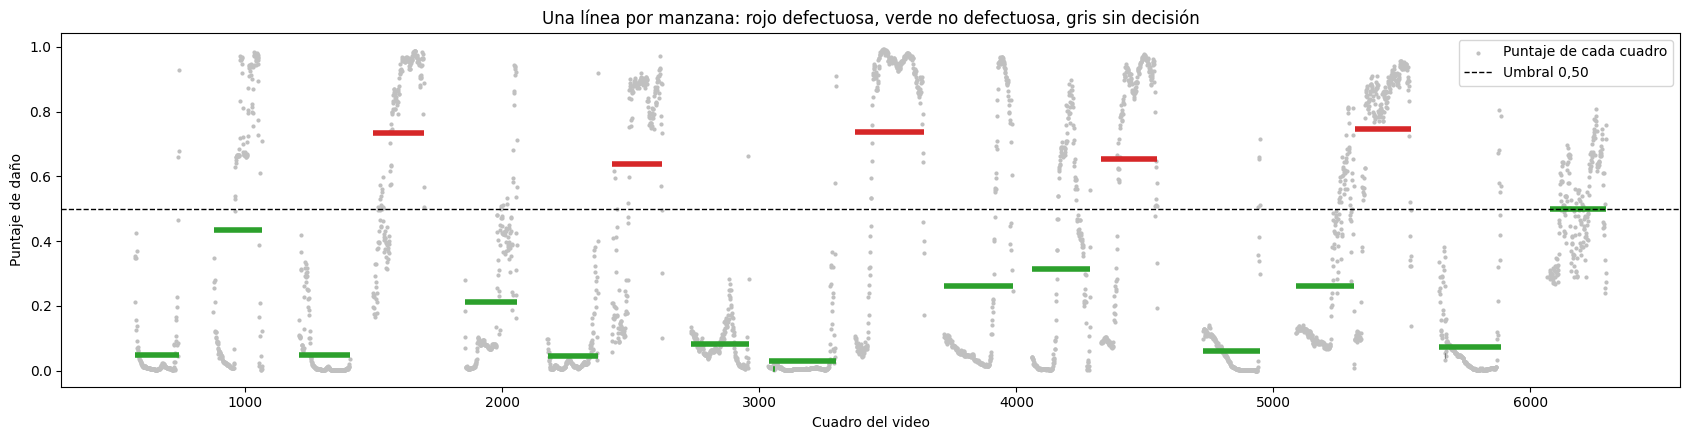

In [11]:
colores = {'defectuosa': 'tab:red', 'no defectuosa': 'tab:green', 'sin decisión': 'gray'}
con_puntaje = [fila for fila in filas if fila['p_danio'] is not None]
plt.figure(figsize=(17, 4.5))
plt.scatter([fila['cuadro'] for fila in con_puntaje], [fila['p_danio'] for fila in con_puntaje],
            s=4, color='silver', label='Puntaje de cada cuadro')
for manzana in manzanas.values():
    plt.hlines(manzana['p_danio'], manzana['desde'], manzana['hasta'],
               color=colores[manzana['estado']], linewidth=4)
plt.axhline(umbral, color='black', linestyle='--', linewidth=1, label='Umbral 0,50')
plt.xlabel('Cuadro del video')
plt.ylabel('Puntaje de daño')
plt.title('Una línea por manzana: rojo defectuosa, verde no defectuosa, gris sin decisión')
plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig(salida / 'puntajes_por_manzana.png', dpi=150)
plt.show()

## Las dos reglas en las mismas 18 pasadas

A cada pasada le asignamos el ID con más cuadros dentro de su tramo y usamos la decisión de ese ID.

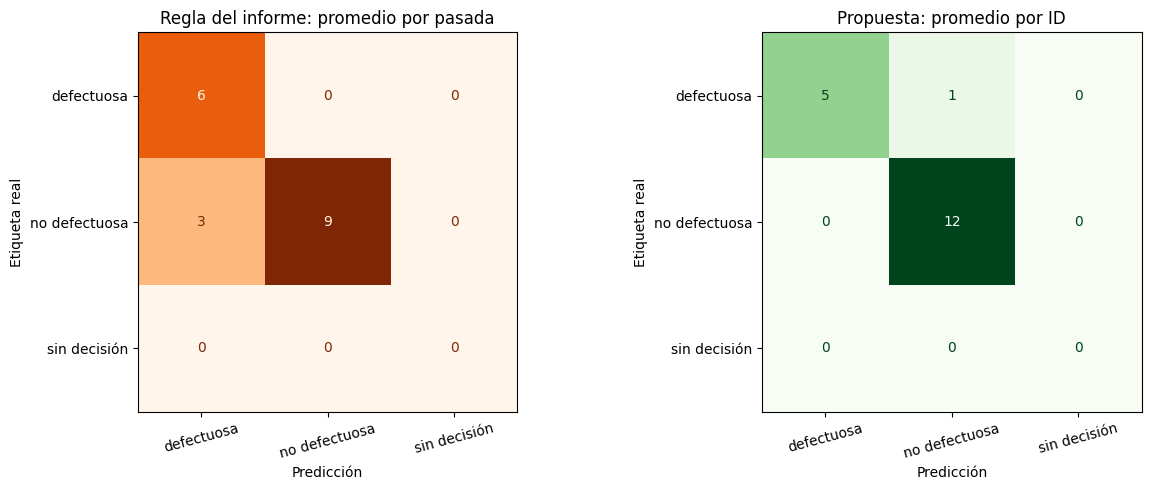

,pasada,real,prediccion,id
0,Pasada 01,no defectuosa,no defectuosa,1
1,Pasada 02,no defectuosa,no defectuosa,2
2,Pasada 03,no defectuosa,no defectuosa,8
3,Pasada 04,defectuosa,defectuosa,9
4,Pasada 05,no defectuosa,no defectuosa,10
5,Pasada 06,no defectuosa,no defectuosa,13
6,Pasada 07,defectuosa,defectuosa,16
7,Pasada 08,no defectuosa,no defectuosa,19
8,Pasada 09,no defectuosa,no defectuosa,20
9,Pasada 10,defectuosa,defectuosa,22


In [12]:
pasadas = []
for referencia in referencias:
    desde, hasta = int(referencia['cuadro_desde']), int(referencia['cuadro_hasta'])
    cuadros_por_id = Counter(fila['id'] for fila in filas
                             if desde <= fila['cuadro'] <= hasta and fila['id'] in manzanas)
    identificador, prediccion = None, 'sin decisión'
    if cuadros_por_id:
        identificador = cuadros_por_id.most_common(1)[0][0]
        prediccion = manzanas[identificador]['estado']
    pasadas.append({'pasada': referencia['manzana'], 'real': referencia['estado'],
                    'prediccion': prediccion, 'id': identificador})

estados = ['defectuosa', 'no defectuosa', 'sin decisión']
reales = [pasada['real'] for pasada in pasadas]
del_informe = [pasada['prediccion'] or 'sin decisión' for pasada in detalle]
por_manzana = [pasada['prediccion'] for pasada in pasadas]

figura, ejes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(reales, del_informe, labels=estados, ax=ejes[0], colorbar=False,
                                        cmap='Oranges', xticks_rotation=15)
ejes[0].set_title('Regla del informe: promedio por pasada')
ConfusionMatrixDisplay.from_predictions(reales, por_manzana, labels=estados, ax=ejes[1], colorbar=False,
                                        cmap='Greens', xticks_rotation=15)
ejes[1].set_title('Propuesta: promedio por ID')
for eje in ejes:
    eje.set_xlabel('Predicción')
    eje.set_ylabel('Etiqueta real')
plt.tight_layout()
plt.savefig(salida / 'confusion.png', dpi=150)
plt.show()
display(pd.DataFrame(pasadas))

## Video con la etiqueta de cada manzana

Dibujamos cada recuadro con la decisión de su ID. La etiqueta ya no cambia entre cuadros de la misma manzana.

In [13]:
por_cuadro = defaultdict(list)
for fila in filas:
    caja = dict(fila)
    manzana = manzanas.get(fila['id'])
    if manzana is None or manzana['estado'] == 'sin decisión':
        caja['p_danio'] = None
    else:
        caja['p_danio'] = manzana['p_danio']
        caja['variedad'] = manzana['variedad']
    por_cuadro[fila['cuadro']].append(caja)

from video import procesar_video

final = salida / 'coral_por_manzana.mp4'
procesar_video(video, final, lambda cuadro, imagen: dibujar(imagen, por_cuadro[cuadro], umbral, fuente))
print(final)

Seis cuadros del video final y un clip de 20 segundos alrededor de la pasada 04.

In [14]:
captura = cv2.VideoCapture(str(final))
figura, ejes = plt.subplots(2, 3, figsize=(18, 7.5))
for eje, referencia in zip(ejes.flat, referencias[::3]):
    captura.set(cv2.CAP_PROP_POS_FRAMES, (int(referencia['cuadro_desde']) + int(referencia['cuadro_hasta'])) // 2)
    ok, imagen = captura.read()
    eje.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
    eje.set_title(f"{referencia['manzana']} · real: {referencia['estado']}")
    eje.axis('off')
captura.release()
plt.tight_layout()
plt.savefig(salida / 'cuadros_del_video.png', dpi=150)
plt.show()

inicio = int(referencias[3]['cuadro_desde']) / fps - 8
clip = salida / 'coral_clip.mp4'
subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-ss', str(inicio), '-t', '20', '-i', str(final),
                '-vf', 'scale=640:-2', '-c:v', 'libx264', '-crf', '28', '-pix_fmt', 'yuv420p', str(clip)],
               check=True)
display(Video(str(clip), embed=True, width=640))

Output hidden; open in https://colab.research.google.com to view.

In [15]:
resumen = {
    'gpu': torch.cuda.get_device_name(0), 'cuadros_por_segundo_sin_guardar_video': cuadros_por_segundo,
    'cruces_contados': contador.total, 'cruces_dentro_del_tramo': cruces_en_tramo,
    'regla_del_informe': por_pasada,
    'propuesta_por_id': {'umbral': umbral, 'minimo_cuadros': minimo_cuadros, 'ids': len(manzanas),
                         'ids_con_decision': len(con_decision),
                         'cuadros_de_ids_con_decision': cuadros_con_decision,
                         'cuadros_que_mostraban_otro_estado': otro_estado,
                         'cuadros_que_mostraban_otra_variedad': otra_variedad, 'pasadas': pasadas},
}
(salida / 'resumen.json').write_text(json.dumps(resumen, indent=2, ensure_ascii=False))
print(json.dumps({clave: valor for clave, valor in resumen.items() if clave != 'propuesta_por_id'},
                 indent=2, ensure_ascii=False))

{
  "gpu": "Tesla T4",
  "cuadros_por_segundo_sin_guardar_video": 68.92807289130518,
  "cruces_contados": 18,
  "cruces_dentro_del_tramo": 16,
  "regla_del_informe": {
    "defectuosa": {
      "total": 6,
      "predicciones": {
        "defectuosa": 6
      }
    },
    "no defectuosa": {
      "total": 12,
      "predicciones": {
        "no defectuosa": 9,
        "defectuosa": 3
      }
    }
  }
}


## Probar un video o la cámara

Para un video propio, subí el MP4 al panel de archivos de Colab y escribí su ruta. Para una cámara USB, indicá parte de su nombre. Las cámaras clasifican por defecto. Con `clasificar = False` se dibujan solo los recuadros, lo más útil en las cintas donde las manzanas se ven pequeñas. Las predicciones en vivo se calculan con el cuadro actual.

In [ ]:
modo = 'desactivado'  # 'video' o 'camara'
archivo = repo / 'videos' / 'manzanas_en_cinta.mp4'  # O Path('/content/mi_video.mp4')
clasificar = modo == 'camara'  # Elegí True para clasificar también las manzanas del MP4.
nombre_camara = ''

if modo == 'video':
    from video import dibujar_cuadro, procesar_video

    inspeccion.reiniciar_seguimiento()

    def anotar(cuadro, imagen):
        cajas = inspeccion.procesar_lote([imagen], imgsz=1280, conf=0.10, max_det=300, clasificar=clasificar)[0]
        return dibujar_cuadro(imagen, cajas, umbral, fuente, clasificar)

    destino = salida / (archivo.stem + '_anotado.mp4')
    procesar_video(archivo, destino, anotar)
    display(Video(str(destino), embed=True, width=640))
elif modo == 'camara':
    from camara import probar_camara

    probar_camara(inspeccion, fuente, salida, nombre_camara=nombre_camara, clasificar=clasificar)
elif modo != 'desactivado':
    raise ValueError('Elegí video, camara o desactivado.')